# What is associated with paid LLM API prices?

This is an individual extension after the UW IS 451 course. The original April-June 2026 group project received **The Most Trendy Technology Award**. My original contributions were screening the dataset from 453 records to 299 paid-model records and writing the initial regression notebook, including full and reduced models without release year. This notebook and the accompanying modules are independently written for reproduction, diagnostics, validation and business-oriented price-deviation analysis.

All results describe associations in the March 31, 2026 snapshot. They do not measure model quality for a specific task or identify causal price effects.

## 1. Verify the input and run the analysis

The download is pinned to Kaggle dataset version 1 and its CSV SHA-256. A changed file stops the analysis. Raw data and complete row-level price comparisons remain local; the public tables contain derived price deviations.

The simple functions in `src/models.py` and `src/validation.py` expose every preparation and modeling step.

In [1]:
# Find the repository and run the verified pipeline from this notebook.
from pathlib import Path
import sys
import warnings
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
assert (ROOT / "src" / "run_analysis.py").exists()
sys.path.insert(0, str(ROOT / "src"))
from run_analysis import run

# Expected historical HC3 limitations remain visible in the coefficient tables.
warnings.filterwarnings("ignore", message="HC3 unavailable:", category=RuntimeWarning)
results = run()

Verified Kaggle v1: llm_price_performance_tracker_2026-03-31.csv (99,892 bytes)
SHA-256: 1c83338dc40f826ce19f3c6d17a3e03970979587fb860dccc79846f691e07177


                 specification   model   n  predictors  r_squared  adjusted_r_squared    f_p_value  hc3_available
              notebook_no_year    full 299          36   0.623230            0.571460 8.682745e-38          False
              notebook_no_year reduced 299          17   0.566571            0.540350 1.626696e-41          False
              report_with_year    full 299          37   0.631892            0.579708 1.857126e-38          False
              report_with_year reduced 299          13   0.574544            0.555137 1.741884e-45          False
              extension_pooled    full 299          22   0.567457            0.532979 2.205856e-38           True
              extension_pooled reduced 299           9   0.515093            0.499992 1.248611e-40           True
sensitivity_no_year_parameters    full 299          20   0.527214            0.493200 1.468108e-34           True
sensitivity_no_year_parameters reduced 299          13   0.505577            0.483025 1.

In [2]:
# Inspect the mutually exclusive screening counts.
display(pd.read_csv(ROOT / "outputs/tables/cleaning_ledger.csv"))

,status,count
0,missing,138
1,zero,16
2,negative,0
3,nonfinite,0
4,paid,299


**Finding:** 138 missing prices and 16 zero prices are removed from 453 rows, leaving 299 positive-price observations. Missing predictors are imputed rather than removed, so the paid-sample count remains 299.

## 2. Reproduce the notebook and report separately

The original notebook excludes release year. The report includes it. Both historical versions use median imputation, creator dummy variables, an intercept and natural log blended price. The reduced model retains predictors with conventional full-model p < 0.05 **once**, then refits once. The code does not choose variables to reach a target R-squared.

,specification,model,n,predictors,r_squared,adjusted_r_squared,f_p_value,hc3_available
0,notebook_no_year,full,299,36,0.623230,0.571460,8.682745e-38,False
1,notebook_no_year,reduced,299,17,0.566571,0.540350,1.626696e-41,False
2,report_with_year,full,299,37,0.631892,0.579708,1.857126e-38,False
3,report_with_year,reduced,299,13,0.574544,0.555137,1.741884e-45,False


,term,report_effect,reproduced_effect,scale
0,aa_intelligence_index,0.28,0.275445,"1 SD of predictor, ddof=0"
1,parameter_count,0.26,0.255143,"1 SD of predictor, ddof=0"
2,release_year,-0.33,-0.332751,"1 SD of predictor, ddof=0"
3,output_tokens_per_second,-0.74,-0.741956,"1 SD of predictor, ddof=0"
4,is_open_source,-1.36,-1.362455,0 to 1


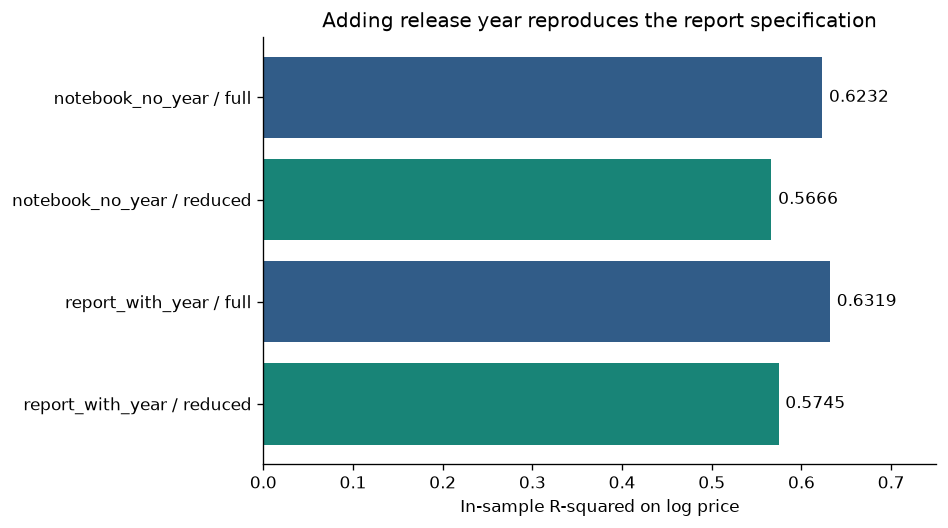

In [3]:
# Compare both historical specifications using the same paid sample.
models = pd.read_csv(ROOT / "outputs/tables/model_comparison.csv")
display(models.loc[models.specification.isin(["notebook_no_year", "report_with_year"])])
display(pd.read_csv(ROOT / "outputs/tables/report_coefficient_check.csv"))
display(Image(filename=str(ROOT / "outputs/figures/reproduction_comparison.png")))

**Finding:** Adding year naturally produces 13 retained predictors and reduced R-squared 0.574544, adjusted R-squared 0.555137. These round to the report's 0.575 and 0.555. The original no-year notebook gives 0.566571 with 17 predictors. The report's other 0.574 label is retained as a documented display difference, without assuming its historical cause.

The feature-effect check uses one standard deviation for continuous predictors and a 0-to-1 contrast for the binary open-source indicator. It matches the displayed effects; the binary effect is not a one-standard-deviation change.

## 3. Diagnose uncertainty and multicollinearity

Historical creator indicators include singleton categories with leverage one. HC3 cannot be estimated reliably for those specifications and is explicitly marked unavailable. For the independent extension, creators with fewer than five training rows are pooled into `Other creators`. This threshold was fixed before viewing validation scores.

VIF is a warning about identifying separate associations, not an automatic variable-deletion rule. No observations are removed because they fit poorly.

In [4]:
# Inspect missing inputs, VIF and robust uncertainty in the extension model.
display(pd.read_csv(ROOT / "outputs/tables/missing_predictors.csv"))
display(pd.read_csv(ROOT / "outputs/tables/vif_extension_pooled_full.csv").sort_values("vif", ascending=False).head(8))
coefficients = pd.read_csv(ROOT / "outputs/tables/coefficients_extension_pooled_full.csv")
display(coefficients.loc[~coefficients.term.str.startswith("provider_"), ["term", "coef", "p_value", "hc3_p_value", "hc3_ci_low", "hc3_ci_high"]])

,feature,missing_rows,paid_rows
0,aa_intelligence_index,2,299
1,output_tokens_per_second,36,299
2,time_to_first_token_s,36,299
3,time_to_first_answer_s,36,299
4,parameter_count,103,299
5,release_year,84,299
6,is_open_source,0,299


,term,vif
18,provider_OpenAI,14.700022
7,provider_Alibaba,12.614132
9,provider_Anthropic,8.747594
6,is_open_source,7.562545
19,provider_Other creators,6.691070
11,provider_Google,6.208338
15,provider_Mistral,5.816650
8,provider_Amazon,5.205307


,term,coef,p_value,hc3_p_value,hc3_ci_low,hc3_ci_high
0,const,716.867999,2.658611e-03,0.038132,39.513339,1394.222660
1,aa_intelligence_index,0.019193,1.030797e-02,0.013250,0.004038,0.034348
2,output_tokens_per_second,-0.005193,4.433257e-11,0.037590,-0.010085,-0.000300
3,time_to_first_token_s,-0.003283,6.053961e-01,0.587648,-0.015189,0.008623
4,time_to_first_answer_s,-0.000504,9.217822e-01,0.908698,-0.009151,0.008142
5,parameter_count,0.001890,2.690851e-05,0.000319,0.000869,0.002910
6,release_year,-0.353264,2.730713e-03,0.038678,-0.688007,-0.018521
7,is_open_source,-1.474550,2.569636e-05,0.000170,-2.235929,-0.713171


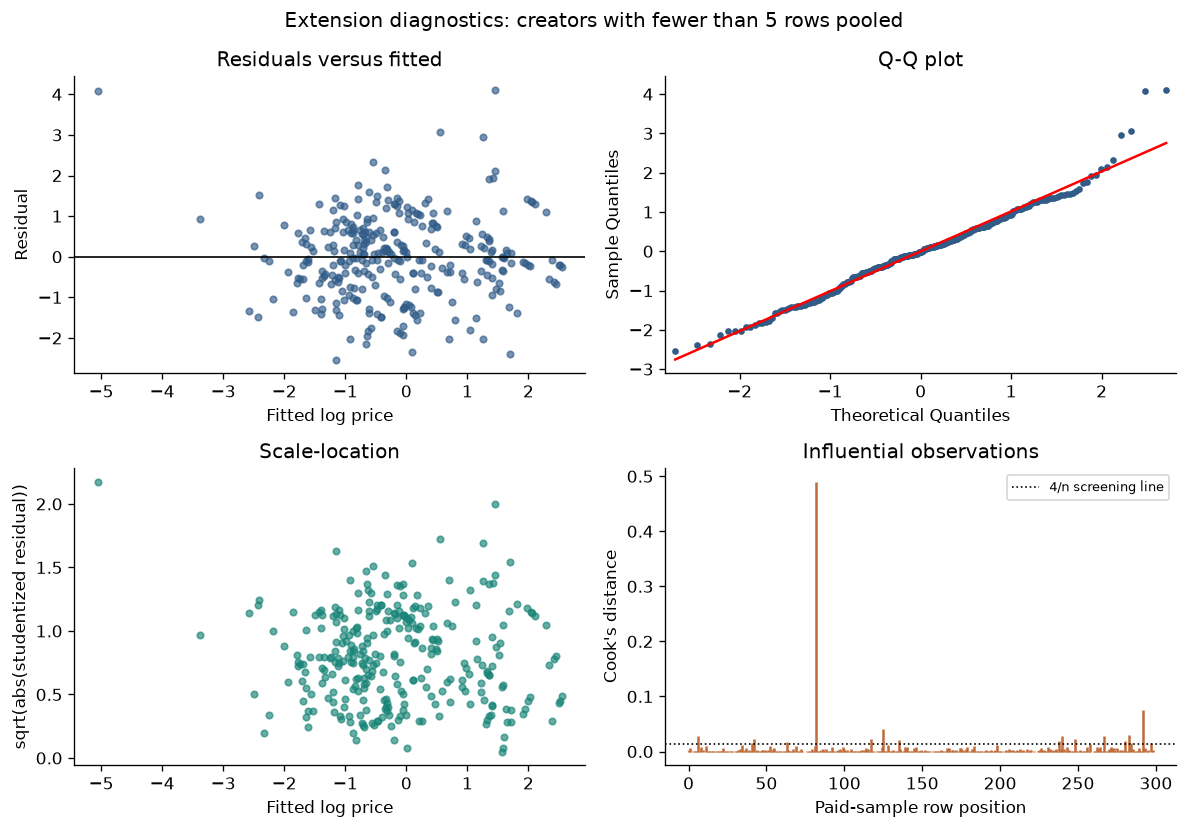

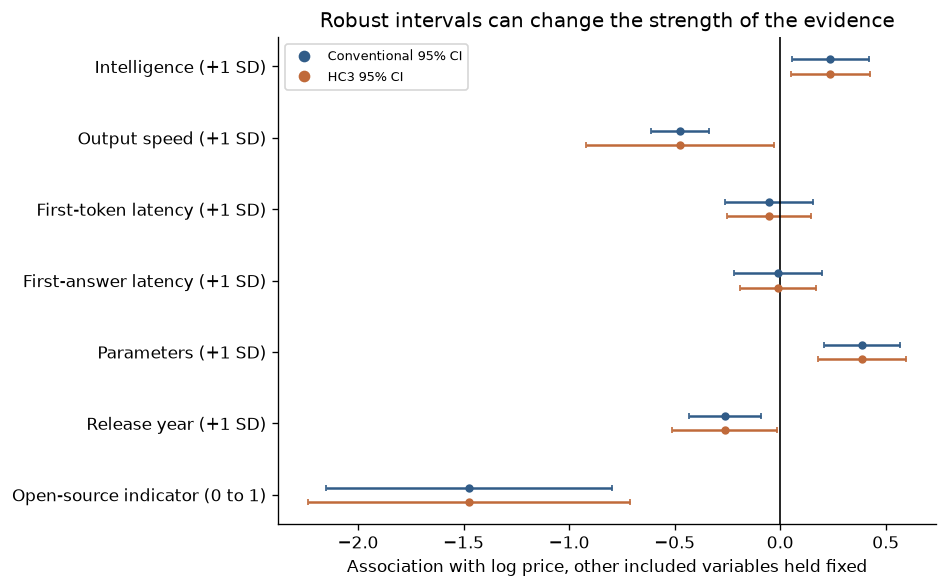

In [5]:
# View residual shape and the change from conventional to HC3 intervals.
display(Image(filename=str(ROOT / "outputs/figures/residual_diagnostics.png")))
display(Image(filename=str(ROOT / "outputs/figures/robust_coefficients.png")))

**Finding:** The pooled full model shows heteroskedasticity (Breusch-Pagan p = 0.00147). HC3 widens uncertainty, especially for output speed: its p value moves from below 0.000001 to about 0.038. Source fields and selection still limit interpretation; robust standard errors do not establish causality or correct measurement error.

## 4. Test performance on held-out base-model groups

Five folds share 198 normalized base-model groups. Reasoning, effort and instruct variants are kept together where recognizable by the documented name rules. Every fold learns imputation, creator pooling, dummy categories and one-pass variable selection from training rows only. The dollar prediction uses that fold's training residuals for a smearing correction.

The full model is the predeclared ranking model. Comparing selected and no-year/no-parameter procedures does not turn their scores into a separate untouched test set.

,model,scope,n,log_mae,log_rmse,price_mae,price_rmse,oof_log_r2
0,full,all,299,0.902036,1.186853,3.800342,16.393991,0.409200
3,reduced,all,299,0.926814,1.224282,3.601033,16.054107,0.371349
6,training_mean,all,299,1.236148,1.549838,4.442670,16.416845,-0.007439
9,without_year_parameters,all,299,0.892157,1.195624,3.763996,16.249223,0.400437


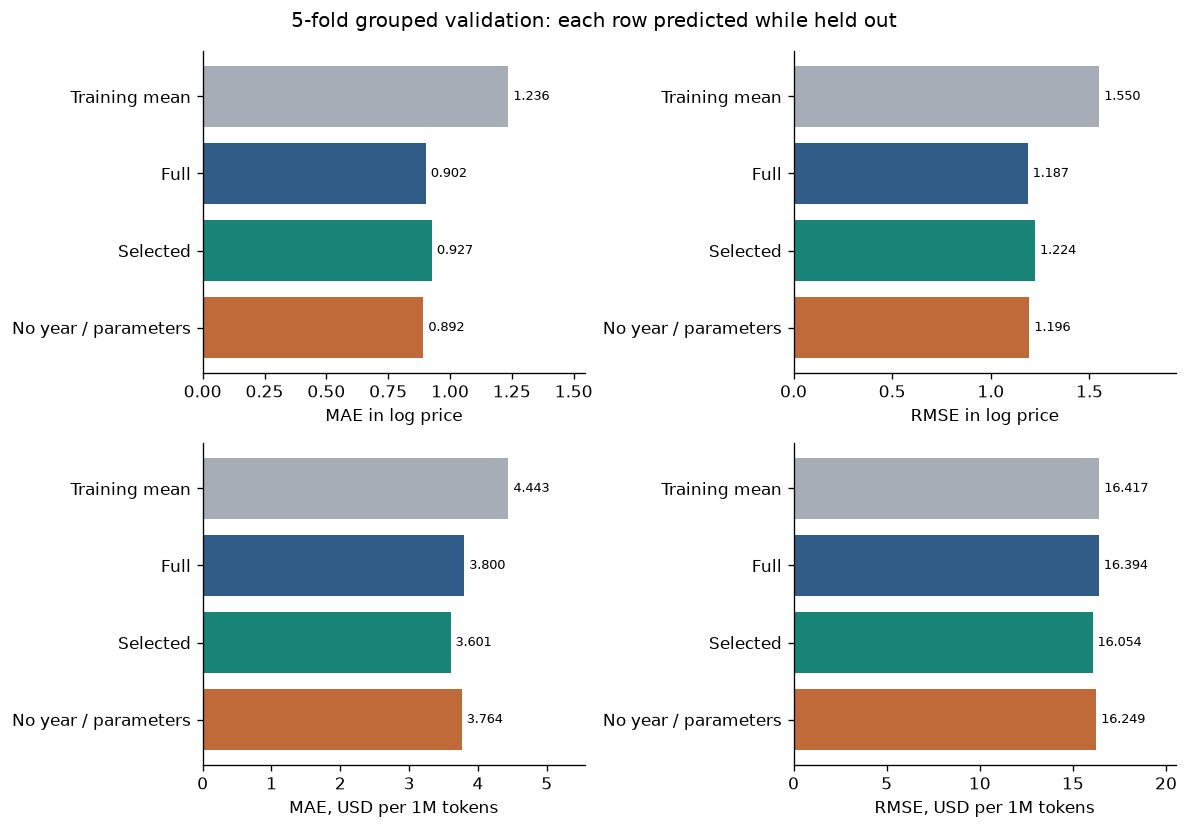

In [6]:
# Compare pooled held-out errors rather than averaging fold R-squared values.
validation = pd.read_csv(ROOT / "outputs/tables/cv_metrics.csv")
display(validation.loc[validation.scope.eq("all")])
display(Image(filename=str(ROOT / "outputs/figures/cross_validation_errors.png")))

**Finding:** The full extension's log-price R-squared falls from 0.567 in sample to 0.409 out of sample. Selection lowers dollar MAE from 3.800 to 3.601 USD per million tokens but worsens log errors. Full-model dollar RMSE of 16.394 remains close to the 16.417 baseline, so fitted prices are a weak basis for large-budget decisions.

## 5. Use price deviations to create a testing shortlist

`price_ratio = observed_price / corrected_held_out_predicted_price`. Below one means below this fitted price benchmark, and above one means above it. It does not mean undervalued, lower quality or better value for every task.

The main ranking covers 160 rows with seen creators, no imputed predictors and no known year error. It does not certify those inputs as accurate. Charts select examples from the 141 eligible rows whose below/above direction agrees across the three tested specifications, with one example per base-model group to avoid filling the chart with configuration variants.

In [7]:
# Read only the derived public ranking, with eligibility and sensitivity flags.
ranking = pd.read_csv(ROOT / "outputs/tables/price_deviation_ranking.csv")
candidates = ranking.loc[ranking.eligible_for_main_ranking & ranking.same_direction_all_specs]
columns = ["model_name", "price_ratio", "deviation_percent", "price_deviation_rank", "pooled_creator"]
display(candidates.drop_duplicates("model_group")[columns].head(8))
display(candidates.sort_values("price_ratio", ascending=False).drop_duplicates("model_group")[columns].head(8))

,model_name,price_ratio,deviation_percent,price_deviation_rank,pooled_creator
0,Gemma 3n E4B Instruct,0.029116,-97.088372,1.0,False
1,Nova Lite,0.038009,-96.199076,2.0,False
2,GPT-5 nano (high),0.043318,-95.668171,3.0,False
3,GLM-5 (Reasoning),0.048377,-95.162334,4.0,False
5,Claude 3 Haiku,0.050563,-94.943720,6.0,False
6,Grok 4 Fast (Reasoning),0.050632,-94.936797,7.0,False
7,Grok 4.1 Fast (Reasoning),0.052983,-94.701667,8.0,False
8,Nova Micro,0.056857,-94.314329,9.0,False


,model_name,price_ratio,deviation_percent,price_deviation_rank,pooled_creator
294,NVIDIA Nemotron 3 Super 120B A12B (Reasoning),6.363005,536.300526,160.0,False
293,o3-pro,5.456268,445.626849,159.0,False
289,Llama 3.1 Instruct 405B,3.981309,298.130896,158.0,False
288,o1,3.747168,274.716806,157.0,False
285,Qwen3 32B (Reasoning),3.436557,243.655730,156.0,False
283,Grok 4.20 Beta 0309 (Non-reasoning),2.779202,177.920170,154.0,False
280,Qwen3 VL 32B (Reasoning),2.647488,164.748787,152.0,False
278,Grok 3,2.576445,157.644477,151.0,False


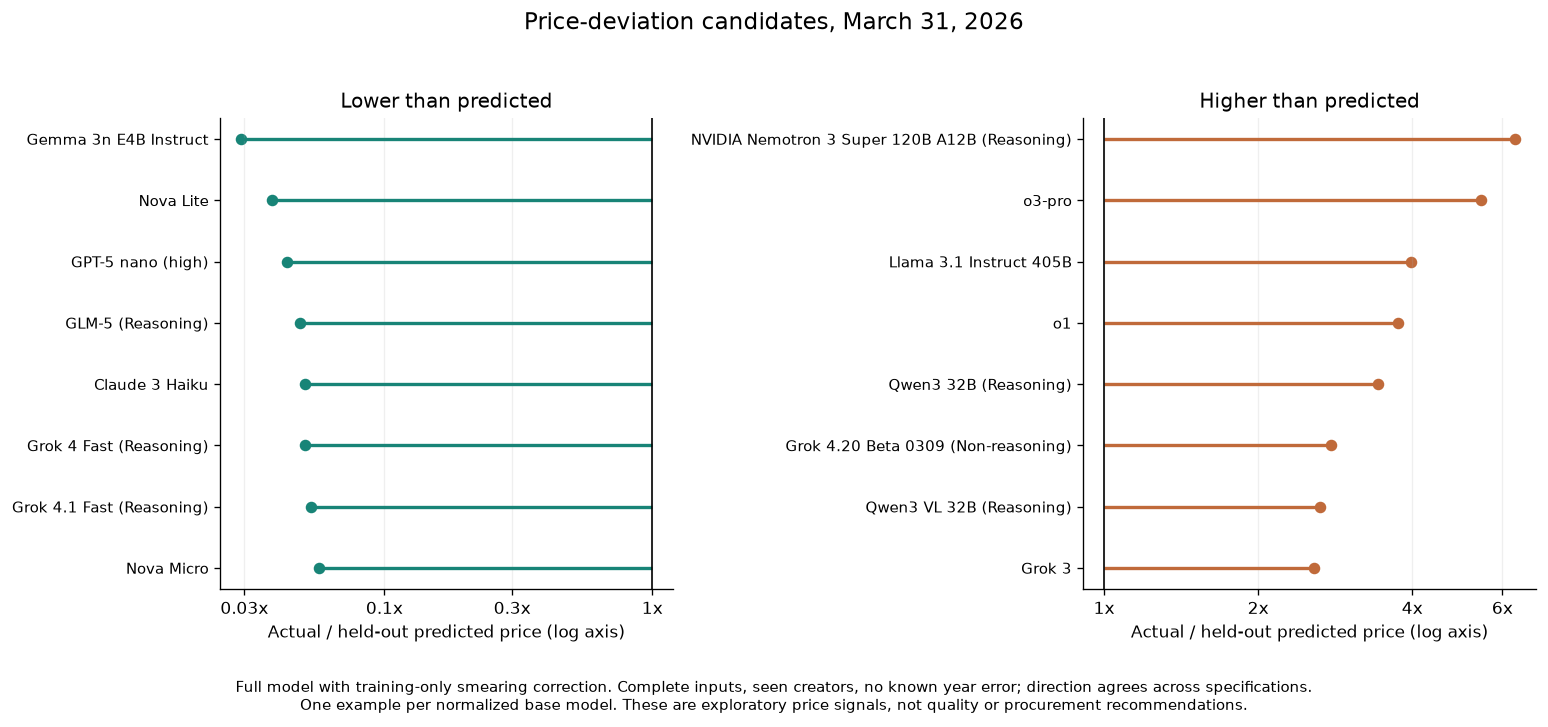

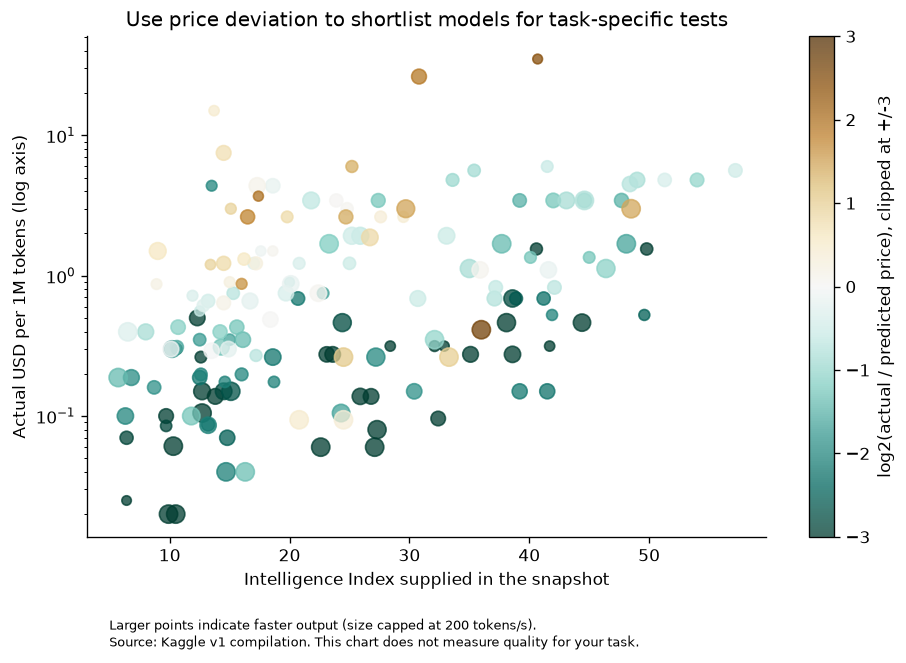

In [8]:
# Put relative price deviation beside capability and speed when shortlisting tests.
display(Image(filename=str(ROOT / "outputs/figures/price_deviation_candidates.png")))
display(Image(filename=str(ROOT / "outputs/figures/business_selection_map.png")))

**Business implication:** Gemma 3n E4B Instruct and Nova Lite are examples below this model's benchmark; o3-pro is above it. A buyer can use these signals to prioritize task-specific evaluations, then check reliability, latency, privacy and actual billing conditions. This analysis does not evaluate those dimensions, and nearby ranks are not statistically established differences.

## Appendix: original price scale

The same 13 report predictors are fitted once to original price as a small function-form comparison. R-squared values for different outcomes cannot be directly ranked as if they measured the same target.

In [9]:
# Inspect the small price-scale appendix without using it as the headline extension.
display(pd.read_csv(ROOT / "outputs/tables/appendix_price_scale.csv"))

,outcome,r_squared,adjusted_r_squared
0,log_price,0.574544,0.555137
1,price,0.098521,0.057401


## Limitations and reproducibility

- One historical snapshot, with no newer version in the checked Kaggle dataset.
- Parameter counts and release years are curated source fields without row-level verification. There are 103 missing parameter counts, 84 missing years, and five known Claude 4.6 year errors. Historical values are preserved; excluding year and parameters is a sensitivity analysis.
- One-pass p-value selection and coefficient tests after selection are exploratory, with no multiplicity adjustment.
- Grouping depends on names, one fixed partition is used, and the smearing factor can remain miscalibrated under heteroskedasticity. HC3 does not account for every possible dependence between model families.
- Kaggle labels the compilation CC0; upstream rights have not been independently verified. Raw source files are not rehosted. See `data/README.md` for sources and the fixed hash.

Run `python src/check_results.py` after the analysis to independently recalculate errors, check training-only medians, verify family separation and confirm input fingerprints. English and Chinese one-page summaries are saved in `outputs/`.